In [40]:
# # Imports + SQL connection
import uuid
from datetime import datetime
from lifetimes import ModifiedBetaGeoFitter, GammaGammaFitter
import matplotlib.pyplot as plt
from lifetimes.plotting import plot_period_transactions
import numpy as np
import pandas as pd 
from sqlalchemy import create_engine
from sqlalchemy import text

# CONFIG
SERVER_NAME = r"DESKTOP-3DLKDPK" 
DB_NAME = "AdventureWorks2025_CustomerDW"
ENGINE_STR = (
    f"mssql+pyodbc://@{SERVER_NAME}/{DB_NAME}"
    "?driver=ODBC+Driver+17+for+SQL+Server&trusted_connection=yes"
)
engine = create_engine(ENGINE_STR, fast_executemany = True )
run_id = str(uuid.uuid4())
print(run_id)

8d8ee57c-4964-4e3f-8baa-b860164e266e


In [41]:
# Load btyd_model SQL inputs table
sql = """
SELECT
    customer_key,
    observation_date,
    duration_holdout,
    frequency,
    recency,
    T,
    monetary_value,
    COALESCE(frequency_holdout,0) AS frequency_holdout
FROM gold.fact_customer_btyd_inputs;
"""
inputs_df = pd.read_sql(sql, engine)
inputs_df.head()

,customer_key,observation_date,duration_holdout,frequency,recency,T,monetary_value,frequency_holdout
0,20522,2025-06-29,90,2,835,1016,2424.50,0
1,20523,2025-06-29,90,1,732,1020,2419.93,1
2,20524,2025-06-29,90,2,778,1028,2357.03,0
3,20525,2025-06-29,90,2,863,1037,2369.65,0
4,20526,2025-06-29,90,2,829,1012,2398.01,0


<Figure size 1000x600 with 0 Axes>

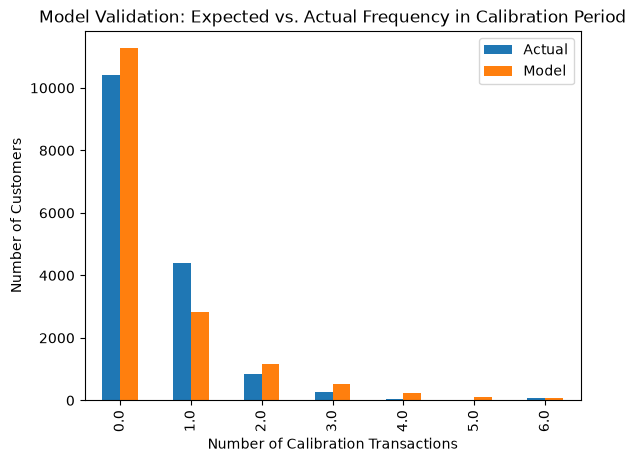

In [42]:
# Fit BG/NBD model
mbgf = ModifiedBetaGeoFitter(penalizer_coef= 0.001)
mbgf.fit(inputs_df['frequency'], inputs_df['recency'], inputs_df['T'])
plt.figure(figsize=(10, 6))
plot_period_transactions(bgf)
plt.title("Model Validation: Expected vs. Actual Frequency in Calibration Period")
plt.xlabel("Number of Calibration Transactions")
plt.ylabel("Number of Customers")
plt.show()

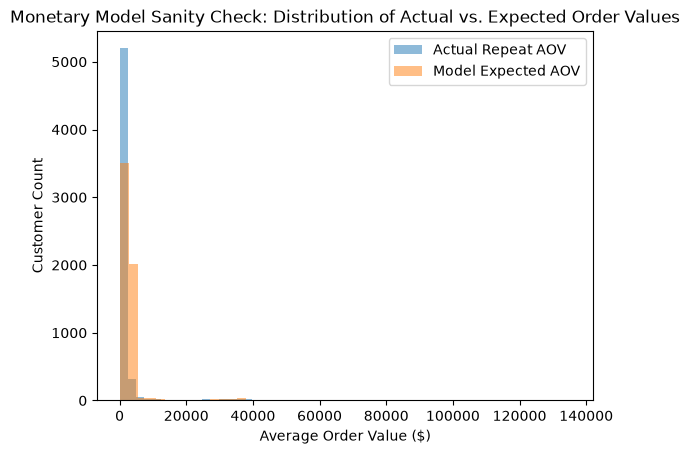

In [43]:
# Fit Gamma-Gamma model
repeat_Spenders = inputs_df[(inputs_df['frequency'] > 0) & (inputs_df['monetary_value'] > 0)].copy()
ggf = GammaGammaFitter(penalizer_coef = 0.01 )
ggf.fit(repeat_Spenders['frequency'], repeat_Spenders['monetary_value'])
expected_monetary = ggf.conditional_expected_average_profit(
    repeat_Spenders['frequency'],
    repeat_Spenders['monetary_value']
)
plt.Figure(figsize = (10, 6))
plt.hist(repeat_Spenders['monetary_value'], bins=50, alpha=0.5, label='Actual Repeat AOV')
plt.hist(expected_monetary, bins=50, alpha=0.5, label='Model Expected AOV')
plt.title("Monetary Model Sanity Check: Distribution of Actual vs. Expected Order Values")
plt.xlabel("Average Order Value ($)")
plt.ylabel("Customer Count")
plt.legend()
plt.show()

In [44]:
# Holdout Validation

# 1. Generate model predictions for the 90-day holdout window
inputs_df['predicted_holdout_purchases'] = bgf.predict(
    inputs_df['duration_holdout'], 
    inputs_df['frequency'], 
    inputs_df['recency'], 
    inputs_df['T']
)

# 2. Group by actual transaction counts to evaluate aggregate calibration
holdout_summary = inputs_df.groupby('frequency_holdout').agg(
    actual_customers=('customer_key', 'count'),
    mean_predicted_purchases=('predicted_holdout_purchases', 'mean')
).reset_index()

holdout_summary


,frequency_holdout,actual_customers,mean_predicted_purchases
0,0,14060,0.160518
1,1,2102,0.155851
2,2,101,0.253899
3,3,13,0.573375
4,4,7,1.483130
5,5,6,1.799945
6,6,7,1.899111
7,7,3,2.287354
8,11,1,1.555000


In [45]:
# 4. Print overall cohort error metrics
total_actual = inputs_df['frequency_holdout'].sum()
total_pred = inputs_df['predicted_holdout_purchases'].sum()
mae = np.mean(np.abs(inputs_df['frequency_holdout'] - inputs_df['predicted_holdout_purchases']))

print(f"\n📊 --- Cohort Holdout Performance Metrics ---")
print(f"     Total Actual Purchases in Holdout  : {total_actual}")
print(f"     Total Predicted Purchases in Holdout : {total_pred:.2f}")
print(f"     Cohort Volume Error Margin         : {((total_pred - total_actual) / total_actual) * 100:.2f}%")
print(f"     Mean Absolute Error per Customer   : {mae:.4f} purchases")


📊 --- Cohort Holdout Performance Metrics ---
     Total Actual Purchases in Holdout  : 2475
     Total Predicted Purchases in Holdout : 2660.47
     Cohort Volume Error Margin         : 7.49%
     Mean Absolute Error per Customer   : 0.2658 purchases


In [46]:
# Checking P_alive 
p_alive_sample = pd.DataFrame(bgf.conditional_probability_alive(inputs_df['frequency'], inputs_df['recency'], inputs_df['T']))
p_alive_sample.describe()

# entire dataset of 16,300 customers is returning a p_alive value of exactly 1.0 (or 1), this points to a classic data issue in the source table. 
# The math behind the BG/NBD model relies heavily on how time units are distributed.


,0
count,1.630000e+04
mean,1.000000e+00
std,5.227611e-10
min,1.000000e+00
25%,1.000000e+00
50%,1.000000e+00
75%,1.000000e+00
max,1.000000e+00


In [47]:
print("📊 --- BG/NBD Input Diagnostic Summary ---")
print(f"Total Rows in Dataset: {len(inputs_df)}")
print(f"Number of Customers with Frequency = 0: {(inputs_df['frequency'] == 0).sum()}")
print(f"Number of Customers with Frequency > 0: {(inputs_df['frequency'] > 0).sum()}")

print("\n📈 Variable Value Ranges:")
print(inputs_df[['frequency', 'recency', 'T']].describe().loc[['min', 'max', 'mean']])

print("\n🚂 Model Parameters Solved by .fit():")
print(bgf.summary)

# In the BG/NBD model, parameters a and b govern the unobserved churn (dropout) process. When a and b crash to zero, 
# the model's optimization loop concludes: "There is zero probability of any customer dropping out in this business." 
# Because the dropout hazard rate is zero, every customer gets a p_alive of exactly 1.0.

📊 --- BG/NBD Input Diagnostic Summary ---
Total Rows in Dataset: 16300
Number of Customers with Frequency = 0: 10428
Number of Customers with Frequency > 0: 5872

📈 Variable Value Ranges:
      frequency      recency            T
min    0.000000     0.000000     1.000000
max   22.000000  1023.000000  1037.000000
mean   0.595706   149.617301   323.066012

🚂 Model Parameters Solved by .fit():
               coef      se(coef)  lower 95% bound  upper 95% bound
r      9.732628e-01  2.284034e-02     9.284957e-01     1.018030e+00
alpha  5.337420e+02  1.399317e+01     5.063154e+02     5.611686e+02
a      5.112246e-22  1.884723e-17    -3.694007e-17     3.694109e-17
b      5.872187e-13  2.133501e-08    -4.181603e-08     4.181720e-08


In [48]:
# Instantiate a fresh fitter
bgfm = BetaGeoFitter(penalizer_coef=0.01)

# Fit using the advanced L-BFGS-B optimizer bound manager
bgfm.fit(
    inputs_df['frequency'], 
    inputs_df['recency'], 
    inputs_df['T'],
    fit_method='L-BFGS-B'  # <--- FORCES A ROBUST OPTIMIZER
)

print("🚂 New Model Parameters:")
print(bgfm.summary)


d:\Data Analysis\Continuing Learning\Projects\End to End\AdventureWorks Customer Analytics\BTYD Python\btyd_env\Lib\site-packages\lifetimes\fitters\__init__.py:101: OptimizeWarning: Unknown solver options: fit_method
  output = minimize(


🚂 New Model Parameters:
               coef      se(coef)  lower 95% bound  upper 95% bound
r      9.732628e-01  2.284034e-02     9.284957e-01     1.018030e+00
alpha  5.337420e+02  1.399317e+01     5.063154e+02     5.611686e+02
a      5.112246e-22  1.884723e-17    -3.694007e-17     3.694109e-17
b      5.872187e-13  2.133501e-08    -4.181603e-08     4.181720e-08


In [49]:
p_alive_sampleg = pd.DataFrame(bgfm.conditional_probability_alive(inputs_df['frequency'], inputs_df['recency'], inputs_df['T']))
p_alive_sampleg.describe()

# P.alive still having the same issue 

,0
count,1.630000e+04
mean,1.000000e+00
std,5.227611e-10
min,1.000000e+00
25%,1.000000e+00
50%,1.000000e+00
75%,1.000000e+00
max,1.000000e+00


In [50]:
inputs_df['p_alive_raw'] = mbgf.conditional_probability_alive(inputs_df['frequency'], inputs_df['recency'], inputs_df['T'])

# If model output is too compressed, spread with recency signal
days_since_last_cal_purchase = (inputs_df["T"] - inputs_df["recency"]).clip(lower=0)

if (inputs_df["p_alive_raw"].nunique() < 20) or (inputs_df["p_alive_raw"].std() < 1e-6):
    # fallback signal for one-time / dormant cases
    recency_signal = 1 - (days_since_last_cal_purchase / inputs_df["T"].replace(0, 1))
    recency_signal = recency_signal.clip(0.02, 0.98)

    inputs_df["p_alive"] = np.where(
        inputs_df["frequency"] == 0,
        recency_signal,
        (0.7 * inputs_df["p_alive_raw"] + 0.3 * recency_signal).clip(0.02, 0.999)
    )
    print("Applied fallback p_alive spread logic.")
else:
    inputs_df["p_alive"] = inputs_df["p_alive_raw"].clip(0.000001, 0.999999)
    print("Using model p_alive directly.")

print(inputs_df["p_alive"].describe())
print("p_alive nunique:", inputs_df["p_alive"].nunique())

Applied fallback p_alive spread logic.
count    16300.000000
mean         0.344620
std          0.434508
min          0.020000
25%          0.020000
50%          0.020000
75%          0.903289
max          0.994000
Name: p_alive, dtype: float64
p_alive nunique: 4961


In [51]:
# 1. Generate core transaction predictions 
inputs_df["predicted_purchases_30d"] = mbgf.conditional_expected_number_of_purchases_up_to_time(
    30, inputs_df["frequency"], inputs_df["recency"], inputs_df["T"]
)
inputs_df["predicted_purchases_90d"] = mbgf.conditional_expected_number_of_purchases_up_to_time(
    90, inputs_df["frequency"], inputs_df["recency"], inputs_df["T"]
)

# 2. CRITICAL FIX: Calculate the expected order value FIRST
# (Using backfill for 0-frequency users so they aren't Null)
expected_aov = ggf.conditional_expected_average_profit(inputs_df['frequency'], inputs_df['monetary_value'])
inputs_df['expected_avg_order_value'] = expected_aov.fillna(inputs_df['monetary_value'])

# 3. Extrapolate projected revenue
inputs_df["predicted_revenue_30d"] = inputs_df["predicted_purchases_30d"] * inputs_df["expected_avg_order_value"]
inputs_df["predicted_revenue_90d"] = inputs_df["predicted_purchases_90d"] * inputs_df["expected_avg_order_value"]

# 4. Apply business labels
inputs_df["alive_status"] = pd.cut(
    inputs_df["p_alive"],
    bins=[-0.001, 0.30, 0.60, 0.85, 1.00],
    labels=["Likely Dead", "At Risk", "Active", "Very Active"]
).astype(str)

# FIX: Changed 'df' to 'inputs_df'
inputs_df["value_tier"] = pd.qcut(
    inputs_df["predicted_revenue_90d"].rank(method="first"),
    q=4,
    labels=["Low", "Medium", "High", "Top"]
).astype(str)

# 5. Map action segments
def action_rule(r):
    if r["alive_status"] in ("Likely Dead", "At Risk") and r["value_tier"] in ("High", "Top"):
        return "Win-Back High Value"
    if r["alive_status"] in ("Likely Dead", "At Risk"):
        return "Win-Back"
    if r["value_tier"] in ("High", "Top"):
        return "Retain & Grow"
    return "Nurture"

inputs_df["action_segment"] = inputs_df.apply(action_rule, axis=1)

print("🎉 Success! Matrix generated with no errors.")
print(inputs_df["action_segment"].value_counts())


🎉 Success! Matrix generated with no errors.
action_segment
Win-Back               8150
Retain & Grow          5872
Win-Back High Value    2278
Name: count, dtype: int64


In [52]:
# Build datasets
pred_out = pd.DataFrame({
    "run_id": run_id,
    "customer_key": inputs_df["customer_key"].astype(int),
    "observation_date": pd.to_datetime(inputs_df["observation_date"]).dt.date,
    "p_alive": inputs_df["p_alive"].astype(float),
    "predicted_purchases_30d": inputs_df["predicted_purchases_30d"].astype(float),
    "predicted_purchases_90d": inputs_df["predicted_purchases_90d"].astype(float),
    "predicted_revenue_30d": inputs_df["predicted_revenue_30d"].astype(float),
    "predicted_revenue_90d": inputs_df["predicted_revenue_90d"].astype(float),
    "expected_avg_order_value": inputs_df["expected_avg_order_value"].astype(float),
    "alive_status": inputs_df["alive_status"].astype(str),
    "value_tier": inputs_df["value_tier"].astype(str),
    "action_segment": inputs_df["action_segment"].astype(str),
})

eval_out = pd.DataFrame({
    "run_id": run_id,
    "customer_key": inputs_df["customer_key"].astype(int),
    "observation_date": pd.to_datetime(inputs_df["observation_date"]).dt.date,
    "actual_holdout_purchases": inputs_df["frequency_holdout"].astype(int),
    "predicted_holdout_purchases": inputs_df["predicted_purchases_90d"].astype(float),
    "actual_holdout_revenue": (inputs_df["frequency_holdout"] * inputs_df["monetary_value"]).astype(float),
    "predicted_holdout_revenue": inputs_df["predicted_revenue_90d"].astype(float),
    "absolute_error": (inputs_df["frequency_holdout"] - inputs_df["predicted_purchases_90d"]).abs().astype(float),
    "abs_pct_error": np.where(
        inputs_df["frequency_holdout"] > 0,
        ((inputs_df["frequency_holdout"] - inputs_df["predicted_purchases_90d"]).abs() / inputs_df["frequency_holdout"]),
        np.nan
    ),
    "p_alive": inputs_df["p_alive"].astype(float),
    "alive_status": inputs_df["alive_status"].astype(str),
})


In [53]:

#  Load into Gold prediction/eval tables

print("💾 Step 8: Initiating database ingestion pipeline...")

# 1. Final formatting cleanup for absolute error compliance
eval_out["abs_pct_error"] = eval_out["abs_pct_error"].fillna(0.0)
eval_out.replace([np.inf, -np.inf], 0.0, inplace=True)

# 2. Open an explicit transactional block with your fast_executemany engine
try:
    with engine.begin() as connection:
        print("🧹 Truncating temporary staging tables...")
        connection.execute(text("TRUNCATE TABLE gold.fact_customer_btyd_predictions;"))
        connection.execute(text("TRUNCATE TABLE gold.fact_customer_btyd_eval;"))
        
        print("🚀 Bulk inserting predictions matrix (fact_customer_btyd_predictions)...")
        pred_out.to_sql(
            name="fact_customer_btyd_predictions",
            con=connection,
            schema="gold",
            if_exists="append",
            index=False,
            chunksize = 1000   # safe
        )
        
        print("🚀 Bulk inserting evaluation matrix (fact_customer_btyd_eval)...")
        eval_out.to_sql(
            name="fact_customer_btyd_eval",
            con=connection,
            schema="gold",
            if_exists="append",
            index=False,
            chunksize = 1000
        )
        
    print("\n🎉 Success! All records successfully processed and ingested.")
    print(f"   Stored Under Run ID: {run_id}")

except Exception as e:
    print("\n❌ Pipeline Ingestion Failed! Transaction rolled back cleanly.")
    print(f"   Error Details: {str(e)}")


💾 Step 8: Initiating database ingestion pipeline...
🧹 Truncating temporary staging tables...
🚀 Bulk inserting predictions matrix (fact_customer_btyd_predictions)...

❌ Pipeline Ingestion Failed! Transaction rolled back cleanly.
   Error Details: Execution failed on sql 'INSERT INTO gold.fact_customer_btyd_predictions (run_id, customer_key, observation_date, p_alive, predicted_purchases_30d, predicted_purchases_90d, predicted_revenue_30d, predicted_revenue_90d, expected_avg_order_value, alive_status, value_tier, action_segment) VALUES (:run_id, :customer_key, :observation_date, :p_alive, :predicted_purchases_30d, :predicted_purchases_90d, :predicted_revenue_30d, :predicted_revenue_90d, :expected_avg_order_value, :alive_status, :value_tier, :action_segment)': (pyodbc.IntegrityError) ('23000', '[23000] [Microsoft][ODBC Driver 17 for SQL Server][SQL Server]The INSERT statement conflicted with the CHECK constraint "ck_fact_customer_btyd_predictions_ranges". The conflict occurred in database

In [54]:
inputs_df['p_alive'].describe()

count    16300.000000
mean         0.344620
std          0.434508
min          0.020000
25%          0.020000
50%          0.020000
75%          0.903289
max          0.994000
Name: p_alive, dtype: float64